# Purity, copy number and clones from bulk WGS with ASCAT and PyClone-VI

A bulk whole-genome sequencing (WGS) study of a tumor usually runs two tools in a chain.
ASCAT estimates the purity and ploidy of each sample and its allele-specific copy number from the read depth and the B-allele frequency (BAF) at heterozygous germline SNPs (Van Loo et al., 2010).
PyClone-VI then groups the point mutations into clusters by their cancer cell fraction (CCF) across the samples and estimates the CCF of each cluster in each sample, using the copy number and purity that ASCAT estimated (Gillis and Roth, 2020).
The CCF of a mutation is the fraction of cancer cells that carry it.
In this tutorial we load a pregrown tumor, sequence three regions of it and a matched normal sample with bulk WGS, run both tools and score each step against the ground truth.
ASCAT and PyClone-VI run from their own conda environments, `iscc-ascat` and `iscc-pyclonevi`.
The notebook runs in about two minutes on a laptop.

In [1]:
%matplotlib inline
import os, tempfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

from iscc import pregrown
from iscc.sample import Resection
from iscc.data import bulkDNA
from iscc.data.human import HumanGenomeLayer
from iscc.integrations import biological_types, clones_from_clades

os.chdir(tempfile.mkdtemp())        # the data and the outputs of the tools go to a scratch directory

## Load a tumor

We load `sweeps`, one of the [pregrown tumors](https://pedrofale.github.io/iscc/reference/#pregrown-tumors), a tumor of about 200,000 cancer cells on a 1 cm field, grown with fewer and stronger drivers than the paper's regime and with immune cells in the stroma.
One driver clone dominates most of its large lesion, a few others occupy sectors of it, and nearly every cancer cell has a doubled genome.
Its genome has one segment per chromosome arm, so that [`HumanGenomeLayer`](https://pedrofale.github.io/iscc/reference/HumanGenomeLayer/) can place every growth gene on its chromosome.
Like every pregrown tumor, it carries a heterozygous germline variant at 30% of its neutral growth genes, about the share of SNPs of a genotyping array that are heterozygous in one person, so that every growth gene stands for one SNP of the array and ASCAT can read the BAF.

In [2]:
tumor = pregrown.sweeps()
print(f"{tumor.get_cancer_size():,} cancer cells of {tumor.get_tumor_size():,} cells after {tumor.time:.0f} generations")
print(f"heterozygous germline sites: {(tumor.germline_zygosity == 'het').sum():,}")

200,003 cancer cells of 585,814 cells after 310 generations
heterozygous germline sites: 1,770


## Sequence three regions and a normal sample

We take three regions of the tumor, as a multi-region study does.
To place them, we materialize the positions and cell types of a subsample of the tissue, which is fast, and split the positions of the cancer cells into three groups with k-means.
Each region contains the demes of one group, and so the cancer cells of that part of the tumor and the normal cells that share their demes, as a macro-dissection would cut it.
The map colors each deme that contains cancer cells by its dominant clone and marks the center of each region.
We dissociate the three regions together, so that their cells share one ground truth, and sequence each region with [`bulkDNA`](https://pedrofale.github.io/iscc/reference/bulkDNA/) at 100x.
The normal cells of the three regions make the matched normal sample, which a study takes from blood.
The dispersion of the depth of the assay is fitted to the WGS of the HG002 benchmark genome, and [Shape the data](03_shape_the_data.ipynb) shows how it compares with other settings.

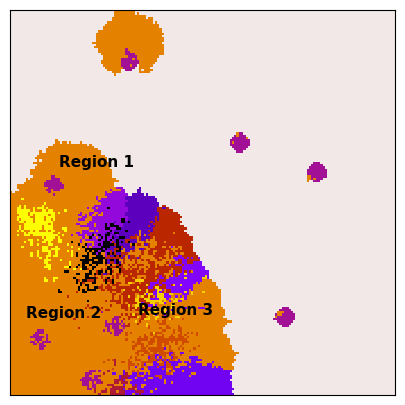

,demes,cells,cancer cells,median coverage
region_1,1383,3594,2549,94.0
region_2,1739,4536,3296,94.0
region_3,1640,4077,2906,94.0


In [3]:
specimen = Resection(tumor)
positions = specimen.dissociate(max_cells=20_000, layers=[])          # positions and cell types only
in_cancer = biological_types(positions["cell_type"]["cell_id"]) == "cancer"
part = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(positions["cell_crd"][in_cancer])
demes = positions["cell_deme"]["deme_id"][in_cancer]
regions = {f"region_{k + 1}": sorted(set(demes[part == k])) for k in range(3)}

ax = tumor.plot_tissue(color="clone", figsize=(5, 5))
for r, ds in regions.items():
    rows, cols = np.divmod(ds, tumor.grid_size)
    ax.text(cols.mean(), rows.mean(), r.replace("_", " ").capitalize(), ha="center", fontsize=11, weight="bold")
plt.show()

cells = specimen.dissociate(region=sum(regions.values(), []), max_cells=12_000, layers="scdna", install=True)
region_of = cells["cell_deme"]["deme_id"].map({d: r for r, ds in regions.items() for d in ds})
cell_type = pd.Series(biological_types(cells["cell_type"]["cell_id"]), index=cells["cell_type"].index)

bulks = {r: bulkDNA(breadth="wgs", mu_depth=100, seed=i).run(
             cells, cell_subset=region_of.index[region_of == r], germline_sites=tumor.germline_sites)
         for i, r in enumerate(regions)}
normal = bulkDNA(breadth="wgs", mu_depth=100, seed=9).run(
    cells, cell_subset=cell_type.index[cell_type != "cancer"], germline_sites=tumor.germline_sites)
pd.DataFrame({"demes": {r: len(ds) for r, ds in regions.items()},
              "cells": region_of.value_counts(),
              "cancer cells": region_of[cell_type == "cancer"].value_counts(),
              "median coverage": {r: b.observed_data["coverage"].median() for r, b in bulks.items()}})

## Write the inputs of ASCAT

ASCAT reads, for every SNP and sample, the log ratio of the tumor depth to the normal depth (logR) and the BAF, with the BAF of the normal sample to find the heterozygous SNPs.
We treat every growth gene as one SNP at the middle of the stretch of its arm that it covers.
The logR of a region is the log ratio of its depth to the depth of the normal sample, each divided by its mean, and centered at zero.
The BAF is the fraction of alternate reads.

In [4]:
os.makedirs("ascat")
layer = HumanGenomeLayer(tumor)
stretch = layer.grid.set_index("growth_gene").sort_index()    # the stretch of its arm each growth gene covers
snps = pd.DataFrame({"chrs": layer.reference.arms["chrom"].str.replace("chr", "").to_numpy()[stretch["arm"]],
                     "pos": ((stretch["lo"] + stretch["hi"]) // 2).to_numpy()}, index=normal.observed_data.index)
depth = lambda b: b.observed_data["coverage"] / b.observed_data["coverage"].mean()
logr = pd.DataFrame({r: np.log2(depth(b) / depth(normal)) for r, b in bulks.items()}).replace([np.inf, -np.inf], np.nan)
tables = {"Tumor_LogR": logr - logr.mean(),
          "Tumor_BAF": pd.DataFrame({r: b.observed_data["vaf"] for r, b in bulks.items()}),
          "Germline_LogR": pd.DataFrame(0.0, index=snps.index, columns=list(bulks)),
          "Germline_BAF": pd.DataFrame({r: normal.observed_data["vaf"] for r in bulks})}
for name, table in tables.items():
    pd.concat([snps, table.round(4)], axis=1).to_csv(f"ascat/{name}.txt", sep="\t")

## Run ASCAT

We run the minimal ASCAT workflow of its documentation for sequencing data with a matched normal, which segments the logR and the BAF jointly with ASPCF at its default penalty and fits purity and ploidy with `gamma` set to 1, as ASCAT requires for sequencing data.
`iscc` draws the GC content of each locus independently of its neighbors, so the GC bias adds noise to the logR of single SNPs but no waves along the genome, and we leave out the GC correction, as the minimal workflow does.
The workflow plots the logR and the BAF of each sample before and after segmentation, and ASCAT writes its log, these plots, its fits and its segments to the working directory.
We print its estimates of purity and ploidy.

In [5]:
%%writefile ascat/ascat.R
# ASCAT (Van Loo et al. 2010) on three tumor samples with a matched normal
suppressPackageStartupMessages(library(ASCAT))
setwd("ascat")
ascat.bc <- ascat.loadData(Tumor_LogR_file = "Tumor_LogR.txt", Tumor_BAF_file = "Tumor_BAF.txt",
                           Germline_LogR_file = "Germline_LogR.txt", Germline_BAF_file = "Germline_BAF.txt",
                           chrs = 1:22, gender = rep("XX", 3), genomeVersion = "hg38")
ascat.plotRawData(ascat.bc)
ascat.bc <- ascat.aspcf(ascat.bc)
ascat.plotSegmentedData(ascat.bc)
ascat.output <- ascat.runAscat(ascat.bc, gamma = 1, write_segments = TRUE)
write.csv(data.frame(purity = ascat.output$purity, ploidy = ascat.output$ploidy), "purity.csv")
write.csv(ascat.output$segments, "segments.csv", row.names = FALSE)

Writing ascat/ascat.R


In [6]:
!~/miniconda3/envs/iscc-ascat/bin/Rscript ascat/ascat.R > ascat/ascat.log 2>&1
purity = pd.read_csv("ascat/purity.csv", index_col=0)
segments = pd.read_csv("ascat/segments.csv")
purity.round(3)

,purity,ploidy
region_1,0.87,2.040
region_2,0.89,2.048
region_3,0.88,2.002


The workflow first plots the logR and the BAF of each sample along the genome, and we show them for the first region.

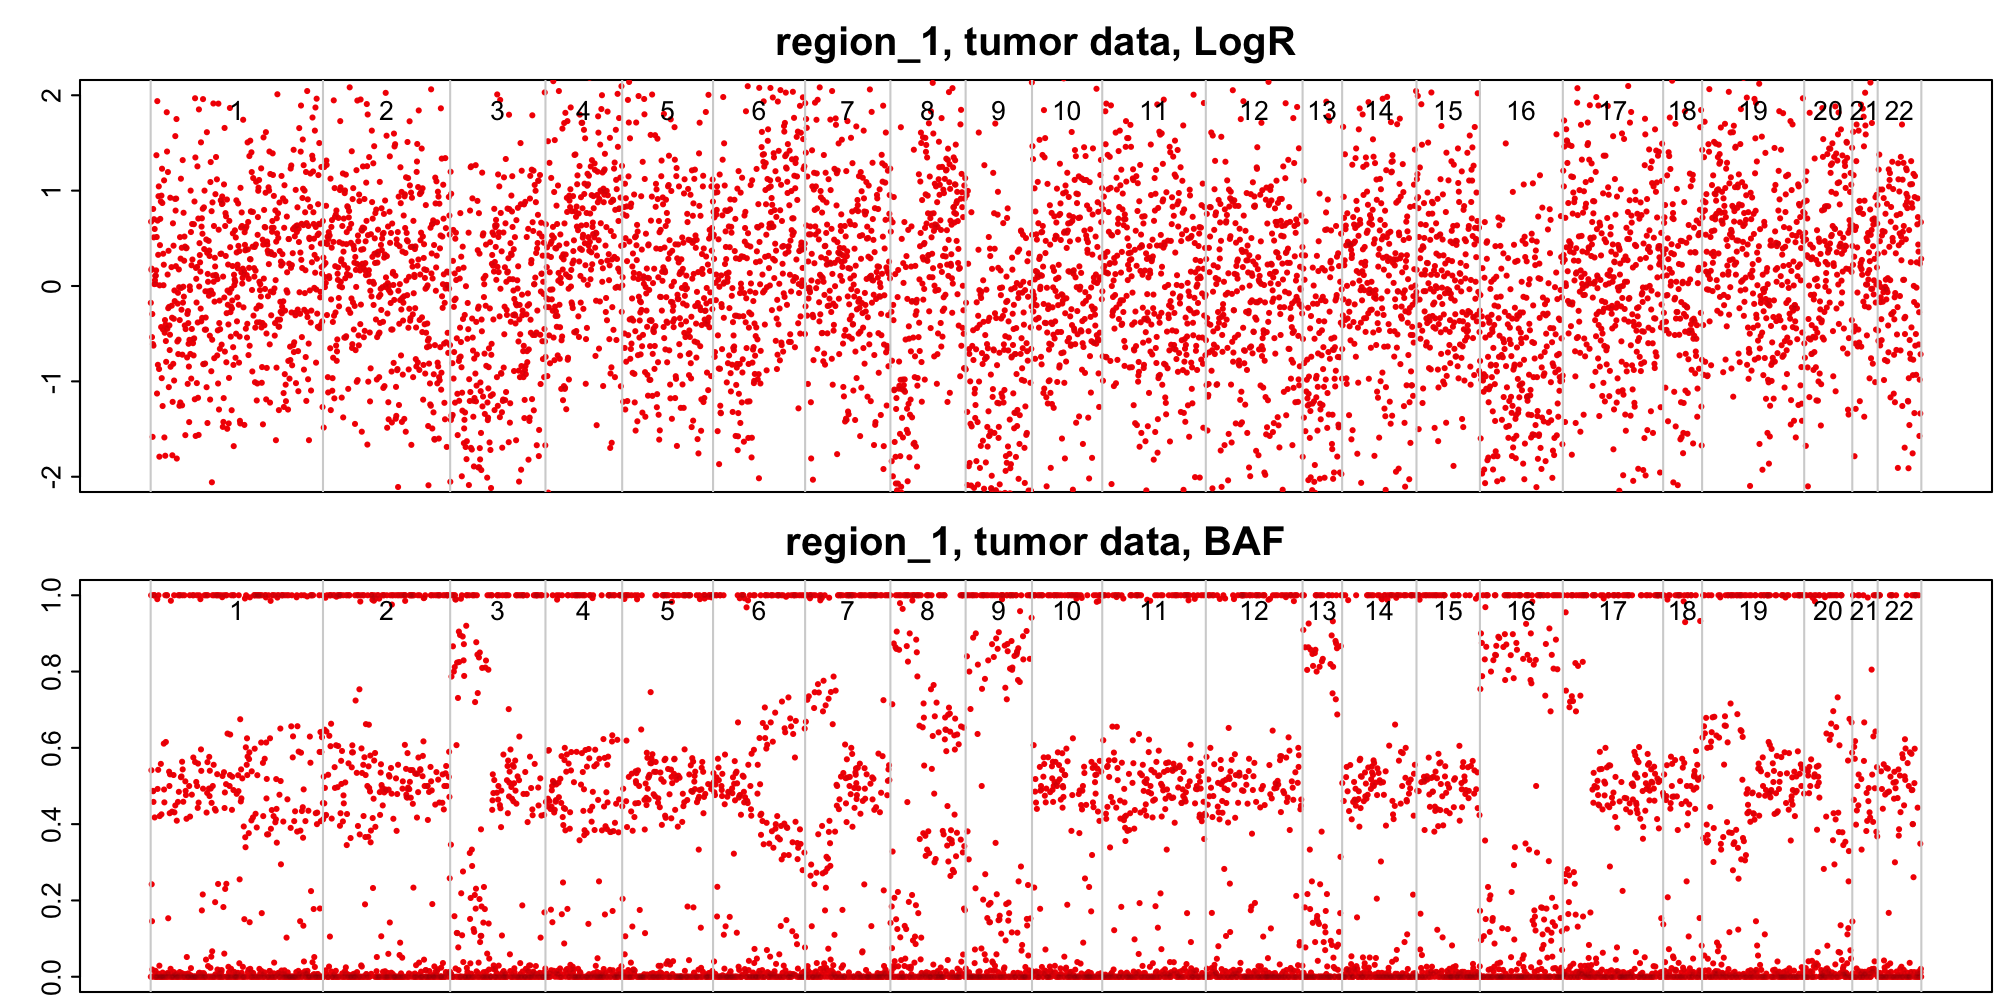

In [7]:
Image("ascat/region_1.tumour.png", width=900)

The logR of single SNPs is noisy.
The BAF of the heterozygous SNPs is near 0.5 on most arms and splits into two bands on the arms where the cancer cells carry unequal copies of the two homologs, such as chromosome 16.
The SNPs at a BAF near 0 or 1 are homozygous in the normal sample, and ASCAT does not use them.
ASPCF segments the logR and the BAF of the heterozygous SNPs jointly, and its plot shows the mean of each segment as a blue line.

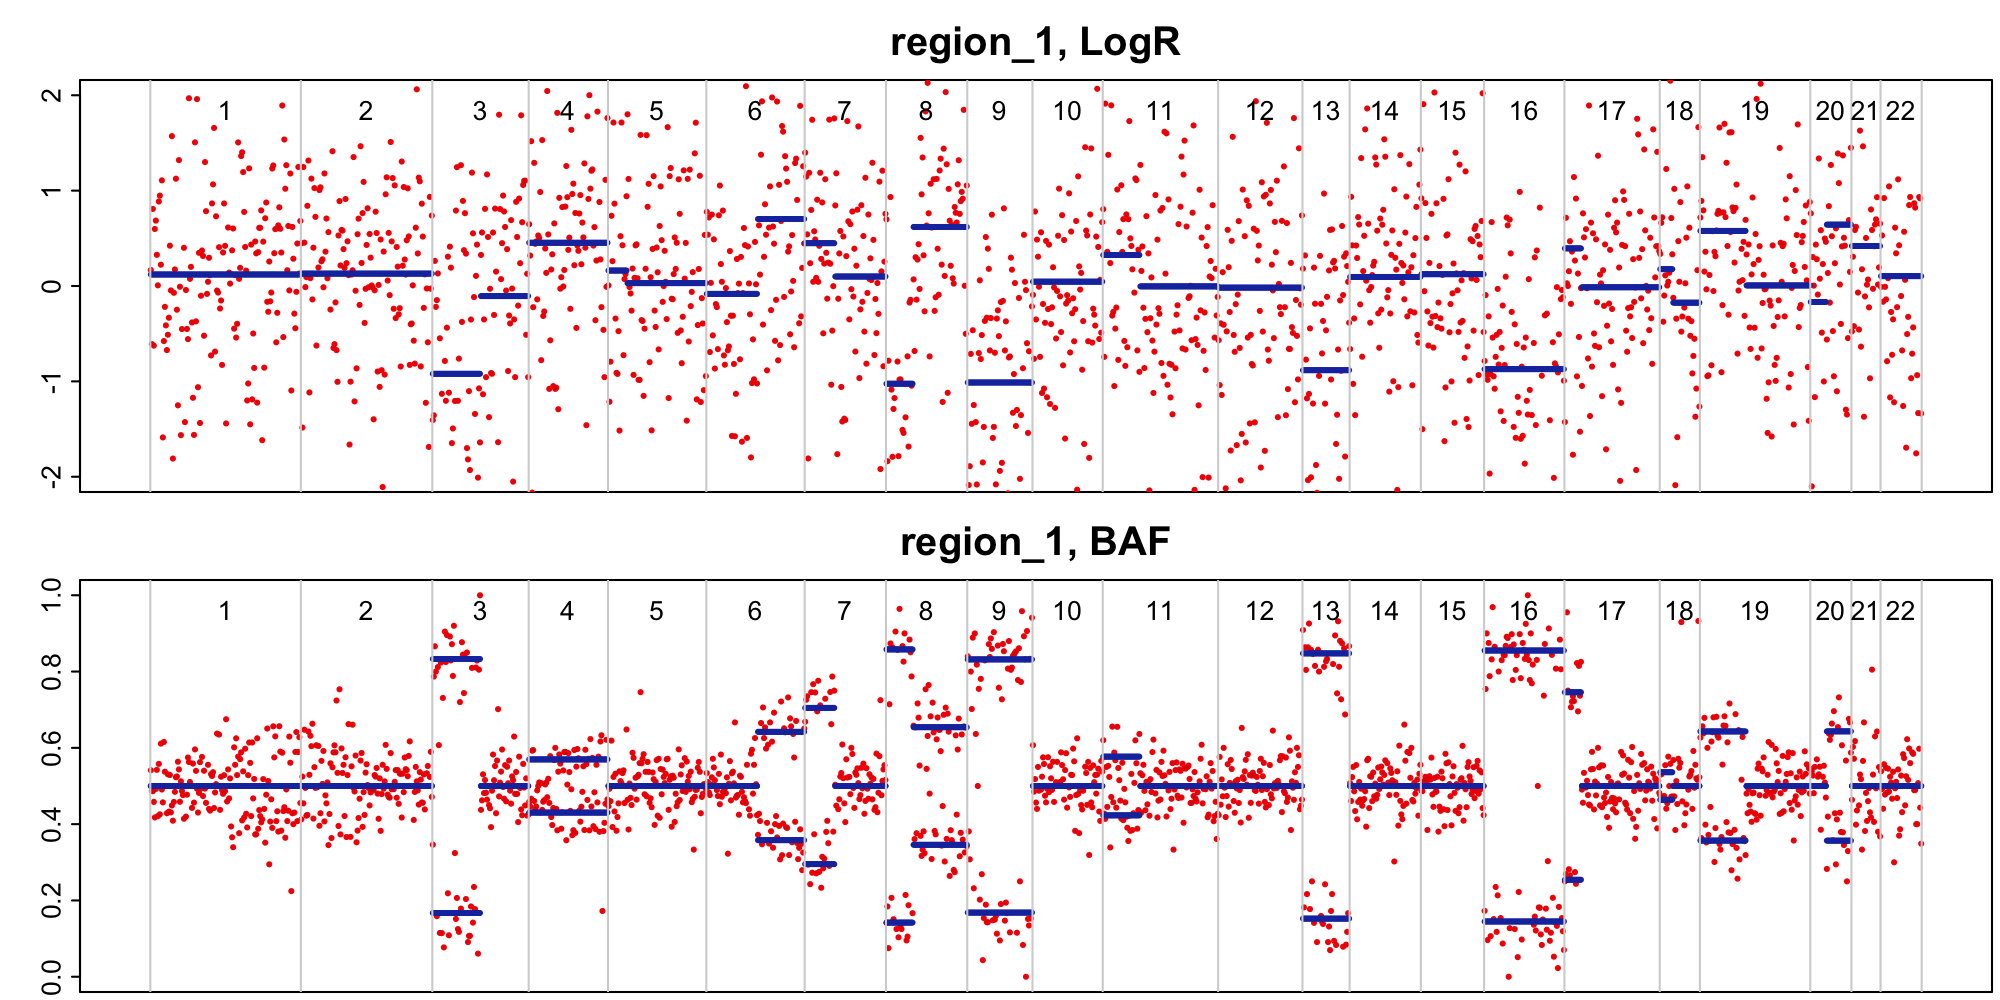

In [8]:
Image("ascat/region_1.ASPCF.png", width=900)

ASCAT then searches for the ploidy and purity that fit the segments best.
Its sunrise plot shows the distance between the data and the fit for each pair of ploidy and purity, darker for a better fit, and marks the chosen pair with a cross.

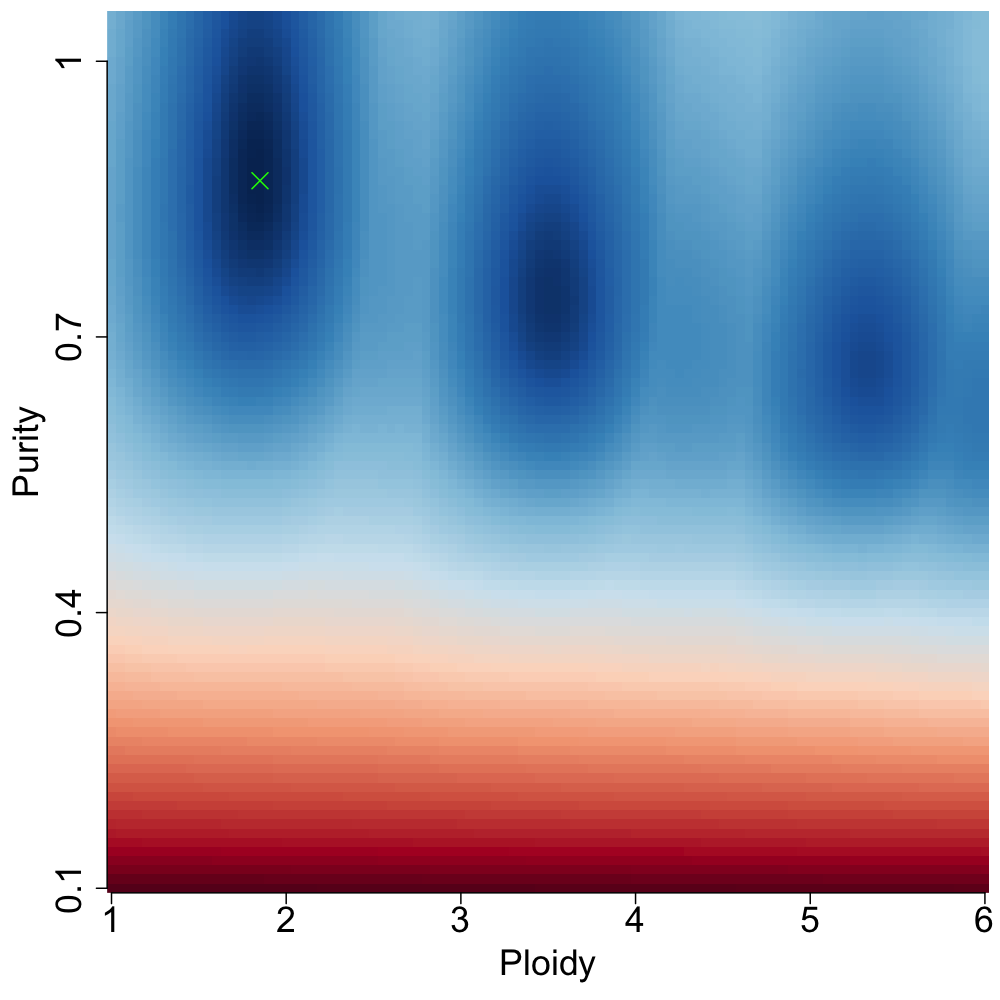

In [9]:
Image("ascat/region_1.sunrise.png", width=400)

For the first region, ASCAT chose a ploidy of about 2 at a purity of about 0.87.
The other dark areas, at about two and three times this ploidy and at lower purity, are the solutions in which every copy number is doubled or tripled, and they fit less well.
ASCAT then plots the allele-specific copy number of each sample, with the major allele in red and the minor allele in blue.
Most arms have one copy of each homolog in all three regions.

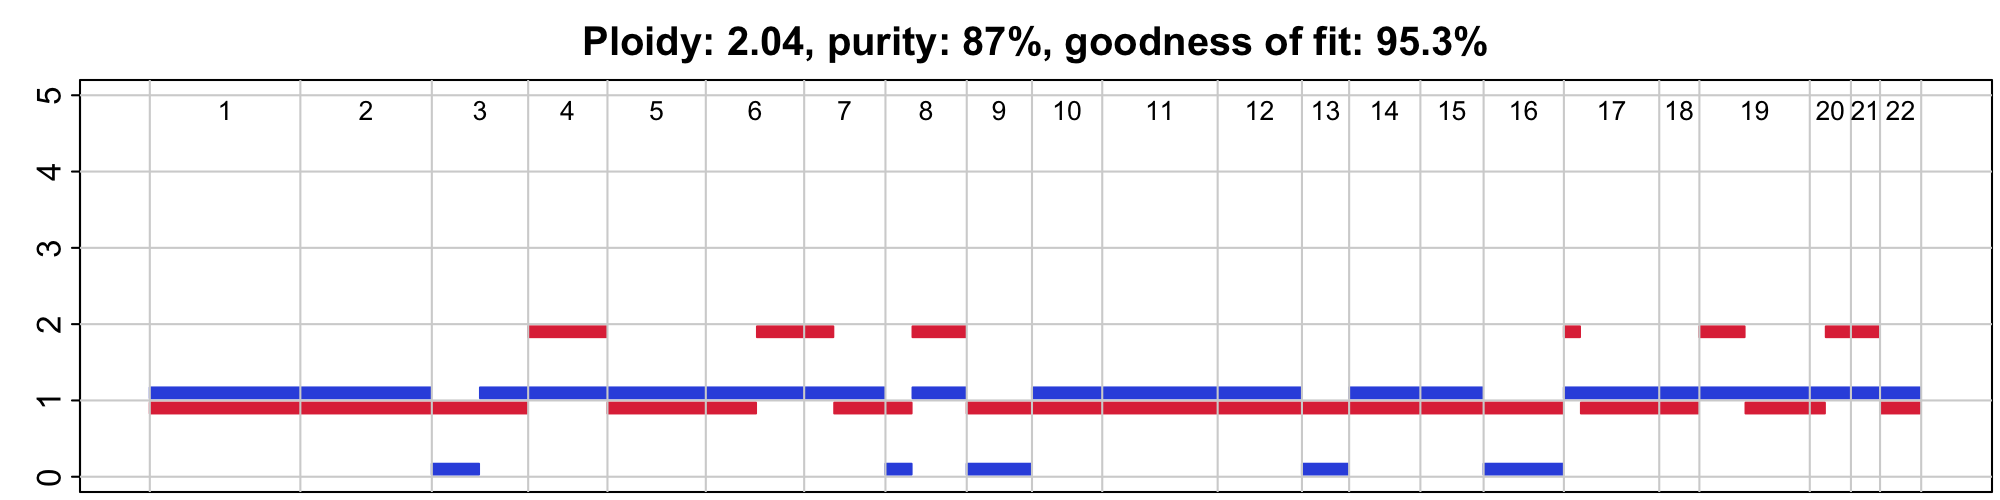

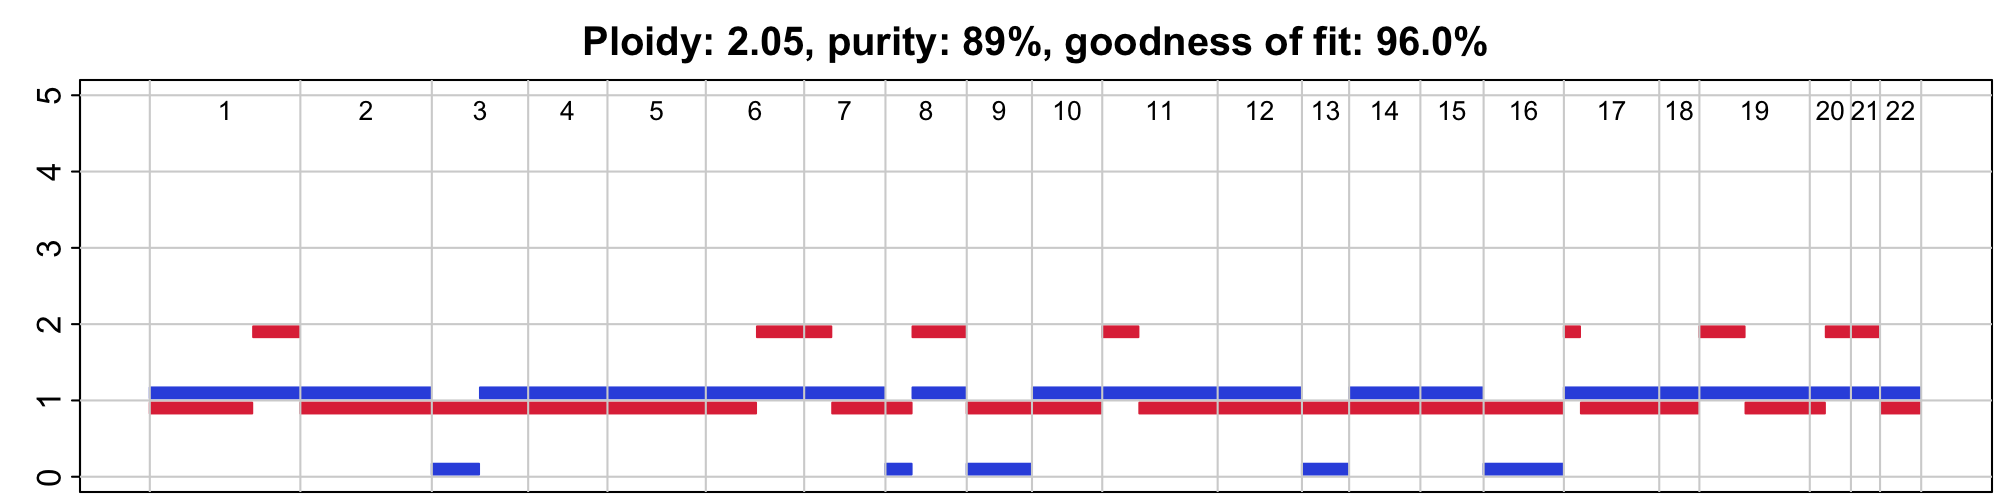

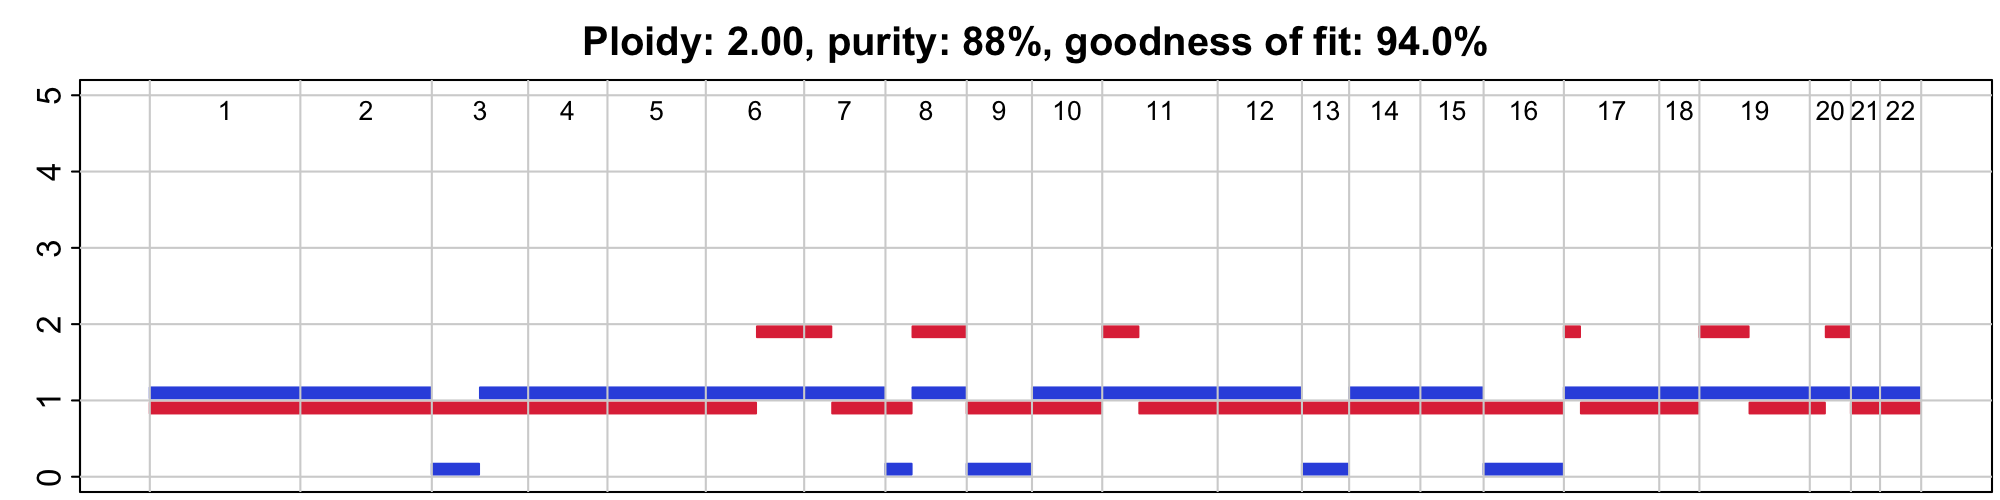

In [10]:
for r in regions:
    display(Image(f"ascat/{r}.ASCATprofile.png", width=900))

## Score purity, ploidy and copy number

The ground truth gives the purity of each region, which is the fraction of its cells that are cancer cells, and the copy number of each homolog of every cancer cell on every arm ([`HumanGenomeLayer`](https://pedrofale.github.io/iscc/reference/HumanGenomeLayer/)).
We take the ploidy of a region as the mean copy number of its cancer cells over the growth genes, and its allele-specific copy number on an arm as the most common pair of major and minor copy numbers among its cancer cells.
We compare them with the estimates of ASCAT, whose copy number on an arm is that of the segment that covers most of the arm.

In [11]:
arms = layer.reference.arms
cancer = cell_type.index[cell_type == "cancer"]
genotype = cells["cell_type"]["cell_id"]
true_cn, true_ploidy = {}, {}
for r in regions:
    in_r = cancer[region_of[cancer] == r]
    cn_p, cn_m = layer.homolog_cn(genotype[in_r], tumor)
    pair = (pd.DataFrame(np.maximum(cn_p, cn_m), columns=arms["arm"]).astype(str) + "+"
            + pd.DataFrame(np.minimum(cn_p, cn_m), columns=arms["arm"]).astype(str))
    true_cn[r] = pair.mode().iloc[0]
    true_ploidy[r] = cells["cell_cnv"].loc[in_r].values.mean()
true_cn = pd.DataFrame(true_cn)                                          # arms x regions

def ascat_arm(sample, arm):
    s = segments[(segments["sample"] == sample) & (segments["chr"].astype(str) == arm.chrom[3:])]
    overlap = np.minimum(s["endpos"], arm.end) - np.maximum(s["startpos"], arm.start)
    best = s.loc[overlap.idxmax()]
    return f"{best.nMajor}+{best.nMinor}"

ascat_cn = pd.DataFrame({r: [ascat_arm(r, a) for a in arms.itertuples()] for r in regions}, index=arms["arm"])
pd.DataFrame({"true purity": {r: b.purity for r, b in bulks.items()}, "ASCAT purity": purity["purity"],
              "true ploidy": true_ploidy, "ASCAT ploidy": purity["ploidy"],
              "arms with the true copy number": (ascat_cn == true_cn).mean()}).round(2)

,true purity,ASCAT purity,true ploidy,ASCAT ploidy,arms with the true copy number
region_1,0.71,0.87,3.94,2.04,0.03
region_2,0.73,0.89,3.97,2.05,0.03
region_3,0.71,0.88,3.97,2.00,0.03


We list the arms where the estimate of ASCAT differs from the ground truth in some region, as major plus minor copy number.

In [12]:
differ = (ascat_cn != true_cn).any(axis=1)
pd.concat({"ground truth": true_cn[differ], "ASCAT": ascat_cn[differ]}, axis=1)

ground truth                      ASCAT                  
        region_1 region_2 region_3 region_1 region_2 region_3
arm                                                          
1p           2+2      2+2      2+2      1+1      1+1      1+1
1q           3+2      3+2      3+2      1+1      2+1      1+1
2p           3+2      3+2      3+2      1+1      1+1      1+1
2q           2+2      2+2      2+2      1+1      1+1      1+1
3p           2+0      2+0      2+0      1+0      1+0      1+0
3q           2+2      2+2      2+2      1+1      1+1      1+1
4p           2+2      2+2      2+2      2+1      1+1      1+1
4q           3+2      3+2      3+2      2+1      1+1      1+1
5p           2+2      2+2      2+2      1+1      1+1      1+1
5q           2+2      2+2      2+2      1+1      1+1      1+1
6p           2+2      2+2      2+2      1+1      1+1      1+1
6q           4+2      4+2      4+2      2+1      2+1      2+1
7p           4+1      4+1      4+1      2+1      2+1      2+1
7q           2+2      2+2      2+2      1+1      1+1      1+1
8p           2+0      2+0      2+0      1+0      1+0      1+0
8q           4+2      4+2      4+2      2+1      2+1      2+1
9q           2+0      2+0      2+0      1+0      1+0      1+0
10p          2+2      2+2      2+2      1+1      1+1      1+1
10q          2+2      2+2      2+2      1+1      1+1      1+1
11p          3+2      3+2      3+2      1+1      2+1      2+1
11q          2+2      2+2      2+2      1+1      1+1      1+1
12p          2+2      2+2      2+2      1+1      1+1      1+1
12q          2+2      2+2      2+2      1+1      1+1      1+1
13q          2+0      2+0      2+0      1+0      1+0      1+0
14q          2+2      2+2      2+2      1+1      1+1      1+1
15q          2+2      2+2      2+2      1+1      1+1      1+1
16p          2+0      2+0      2+0      1+0      1+0      1+0
16q          2+0      2+0      2+0      1+0      1+0      1+0
17p          4+1      4+1      4+1      2+1      2+1      2+1
17q          2+2      2+2      2+2      1+1      1+1      1+1
18p          2+2      2+2      2+2      1+1      1+1      1+1
18q          2+2      2+2      2+2      1+1      1+1      1+1
19p          4+2      4+2      4+2      2+1      2+1      2+1
19q          2+2      2+2      2+2      1+1      1+1      1+1
20p          2+2      2+2      2+2      1+1      1+1      1+1
20q          4+2      4+2      4+2      2+1      2+1      2+1
21q          3+2      3+2      3+2      2+1      2+1      1+1
22q          2+2      2+2      2+2      1+1      1+1      1+1

The cancer cells of all three regions have a doubled genome, with a true ploidy of about 4.
In all three regions, ASCAT chose the solution at half of the true ploidy (2.04, 2.05 and 2.00 against 3.94, 3.97 and 3.97), at a purity 0.16 to 0.17 above the truth, and called most arms at about half of their true copy number, so that its allele-specific copy number is right on 3% of the arms of each region.
The solution at the true ploidy is the second dark area of the sunrise plot of region 1, and it fit less well than the one ASCAT chose.
A doubled genome and its half give the same relative copy numbers, so the logR and the BAF alone can favor either of them, and only an independent measure of ploidy, such as single-cell DNA or flow cytometry, tells them apart.

## Write the input of PyClone-VI

PyClone-VI reads, for every mutation in every sample, the reference and alternate read counts, the major and minor copy number of the cancer cells at the locus, the copy number of the normal cells and the purity of the sample (its tumor content).
We call a mutation at every locus with at least three alternate reads in some region, and drop the germline variants, which ASCAT read from the normal sample.
We give each mutation the major and minor copy number of the ASCAT segment that contains it in each region, and the purity that ASCAT estimated.
PyClone-VI needs at least one major copy, so we leave out the mutations in a segment without copies in some region.

In [13]:
reads = pd.concat({r: b.observed_data for r, b in bulks.items()}, names=["sample_id", "mutation_id"]).reset_index()
reads = reads[~reads["is_germline"]]
reads = reads[reads.groupby("mutation_id")["alt_counts"].transform("max") >= 3]

def ascat_segment(sample, mutation):
    chrom, pos = snps.loc[mutation, "chrs"], snps.loc[mutation, "pos"]
    s = segments[(segments["sample"] == sample) & (segments["chr"].astype(str) == chrom)
                 & (segments["startpos"] <= pos) & (segments["endpos"] >= pos)]
    return s.iloc[0] if len(s) else pd.Series({"nMajor": 0, "nMinor": 0})

cn = pd.DataFrame([ascat_segment(r, m)[["nMajor", "nMinor"]] for r, m in zip(reads["sample_id"], reads["mutation_id"])])
pyclone = pd.DataFrame({"mutation_id": reads["mutation_id"].to_numpy(), "sample_id": reads["sample_id"].to_numpy(),
                        "ref_counts": (reads["coverage"] - reads["alt_counts"]).to_numpy(),
                        "alt_counts": reads["alt_counts"].to_numpy(),
                        "major_cn": cn["nMajor"].astype(int).to_numpy(), "minor_cn": cn["nMinor"].astype(int).to_numpy(),
                        "normal_cn": 2, "tumour_content": purity.loc[reads["sample_id"], "purity"].to_numpy()})
lost = pyclone.loc[pyclone["major_cn"] == 0, "mutation_id"].unique()
pyclone = pyclone[~pyclone["mutation_id"].isin(lost)]
os.makedirs("pyclonevi")
pyclone.to_csv("pyclonevi/input.tsv", sep="\t", index=False)
print(f"{pyclone['mutation_id'].nunique()} mutations in 3 regions, {len(lost)} left out at copy number 0")

602 mutations in 3 regions, 0 left out at copy number 0


## Run PyClone-VI

We run PyClone-VI with the command of its documentation, which allows at most 40 clusters, uses the beta-binomial density for deep sequencing and restarts the variational inference 10 times, and fix the seed.
We print the final evidence lower bound (ELBO) and the number of clusters.

In [14]:
!~/miniconda3/envs/iscc-pyclonevi/bin/pyclone-vi fit -i pyclonevi/input.tsv -o pyclonevi/fit.h5 -c 40 -d beta-binomial -r 10 --seed 1 | grep -E "Final ELBO|Number of clusters used" | tail -2
!~/miniconda3/envs/iscc-pyclonevi/bin/pyclone-vi write-results-file -i pyclonevi/fit.h5 -o pyclonevi/results.tsv > /dev/null

Final ELBO: -4578.10894557751
Number of clusters used: 4


PyClone-VI writes its results as a table, without plots, and gives all the mutations of a cluster the same CCF.
A multi-region study plots the allele fraction of every mutation in one region against its allele fraction in another, colored by cluster, as the `plot_loci` command of PyClone did (`vaf_scatter`).

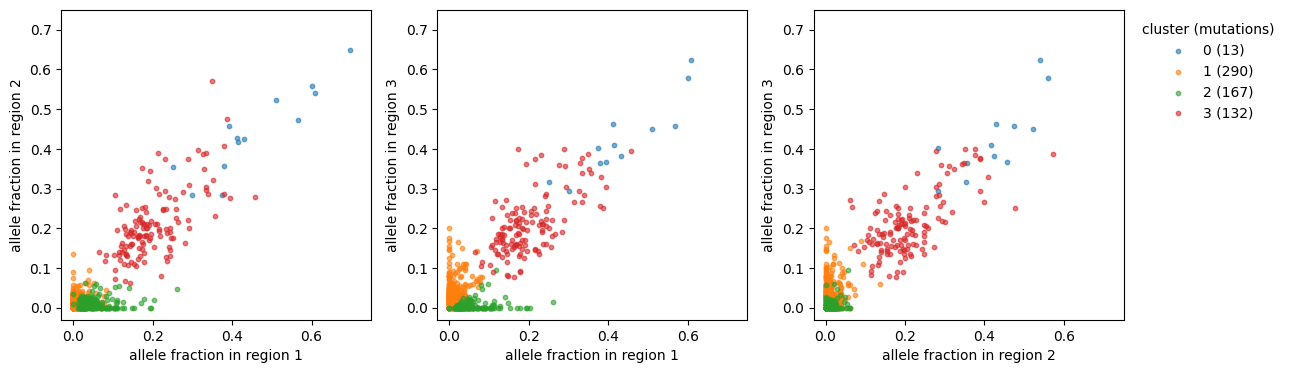

In [15]:
result = pd.read_csv("pyclonevi/results.tsv", sep="\t")
cluster = result.drop_duplicates("mutation_id").set_index("mutation_id")["cluster_id"]
vaf = (pyclone.assign(vaf=pyclone["alt_counts"] / (pyclone["ref_counts"] + pyclone["alt_counts"]))
       .pivot(index="mutation_id", columns="sample_id", values="vaf").loc[cluster.index])
colors = dict(zip(sorted(cluster.unique()), plt.get_cmap("tab10").colors))
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (a, b) in zip(axes, [("region_1", "region_2"), ("region_1", "region_3"), ("region_2", "region_3")]):
    for c, muts in vaf.groupby(cluster):
        ax.scatter(muts[a], muts[b], color=colors[c], s=10, alpha=0.6, label=f"{c} ({len(muts)})")
    ax.set(xlabel=f"allele fraction in {a.replace('_', ' ')}", ylabel=f"allele fraction in {b.replace('_', ' ')}",
           xlim=(-0.03, 0.75), ylim=(-0.03, 0.75))
    ax.set_aspect("equal")
axes[-1].legend(title="cluster (mutations)", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()

The mutations of clusters 0 and 3 have high allele fractions in every region, and those of cluster 2 in region 1 only.
The 290 mutations of cluster 1 have low allele fractions in every region.
The allele fractions of the mutations of one cluster spread more than their CCFs, since they also depend on the copy number at each mutation and on the purity of each region.

## Score the clusters and the CCFs

The ground truth records which cancer cells carry each mutation, and the true CCF of a mutation in a region is the fraction of the cancer cells of the region that carry it.
To compare clusters, we label each cancer cell with its clone, which is the clade of the true genealogy that contains the cell ([`clones_from_clades`](https://pedrofale.github.io/iscc/reference/clones_from_clades/)), and keep the clades with at least 3% of the cancer cells.
We then label each mutation with the set of clones in which most cells carry it, and name each set by the numbers of its clones.
Cancer cells above every clade share the label `other`, and the mutations that most cells of no clone carry get the label `none`.
Mutations with the same set of clones have nearly the same CCF in every region, which is what a cluster of PyClone-VI represents.
We compare the clusters with the sets of clones by the adjusted Rand index, which is 1 for identical groupings and close to 0 for random ones, and list, for each cluster, its number of mutations and the mean of the estimated and of the true CCF in each region.

In [16]:
mutations = pyclone["mutation_id"].unique()
carried = cells["cell_snv"].loc[cancer, mutations] > 0
true_ccf = carried.groupby(region_of[cancer]).mean()                         # regions x mutations
clone = clones_from_clades(tumor, min_cells=int(0.03 * len(cancer)))[cancer].astype(str)
in_clone = carried.groupby(clone).mean() > 0.5                                 # clones x mutations
true_set = in_clone.apply(lambda c: "+".join(c.index[c].str.replace("clone_", "")) or "none")

result["true_ccf"] = [true_ccf.at[r, m] for r, m in zip(result["sample_id"], result["mutation_id"])]
cluster = result.drop_duplicates("mutation_id").set_index("mutation_id")["cluster_id"]
print(f"{cluster.nunique()} clusters for {true_set.nunique()} sets of clones")
print(f"mean absolute error of the CCF: {(result['cellular_prevalence'] - result['true_ccf']).abs().mean():.3f}")
print(f"adjusted Rand index against the sets of clones: {adjusted_rand_score(true_set[cluster.index], cluster):.2f}")

mean_ccf = lambda column: result.pivot_table(index="cluster_id", columns="sample_id", values=column)
summary = pd.concat({"PyClone-VI": mean_ccf("cellular_prevalence"), "ground truth": mean_ccf("true_ccf")}, axis=1)
summary.insert(0, "mutations", cluster.value_counts())
summary.round(2)

4 clusters for 37 sets of clones
mean absolute error of the CCF: 0.144
adjusted Rand index against the sets of clones: 0.27


mutations PyClone-VI                   ground truth           \
sample_id              region_1 region_2 region_3     region_1 region_2   
cluster_id                                                                
0                 13       0.96     0.87     0.93         0.97     0.98   
1                290       0.02     0.03     0.07         0.05     0.05   
2                167       0.11     0.02     0.01         0.21     0.05   
3                132       0.42     0.45     0.44         0.83     0.89   

                     
sample_id  region_3  
cluster_id           
0              0.98  
1              0.12  
2              0.04  
3              0.89

We count the mutations of each set of clones in each cluster, and plot the estimated against the true CCF of every mutation in each region, colored by cluster.

In [17]:
pd.crosstab(true_set[cluster.index].rename("set of clones"), cluster.rename("cluster"))

cluster,0,1,2,3
set of clones,,,,
1,0,15,1,0
1+10+11+2+3+4+5+6+7+8+9+other,11,0,0,3
1+10+11+2+3+5+6+7+8+9+other,2,0,0,125
1+10+11+2+3+5+6+7+9+other,0,0,0,2
1+10+11+2+5+6+7+8+9+other,0,0,0,1
1+6,0,2,0,0
1+7,0,1,0,0
10,0,1,2,0
10+11+6+7+8+9,0,0,1,0


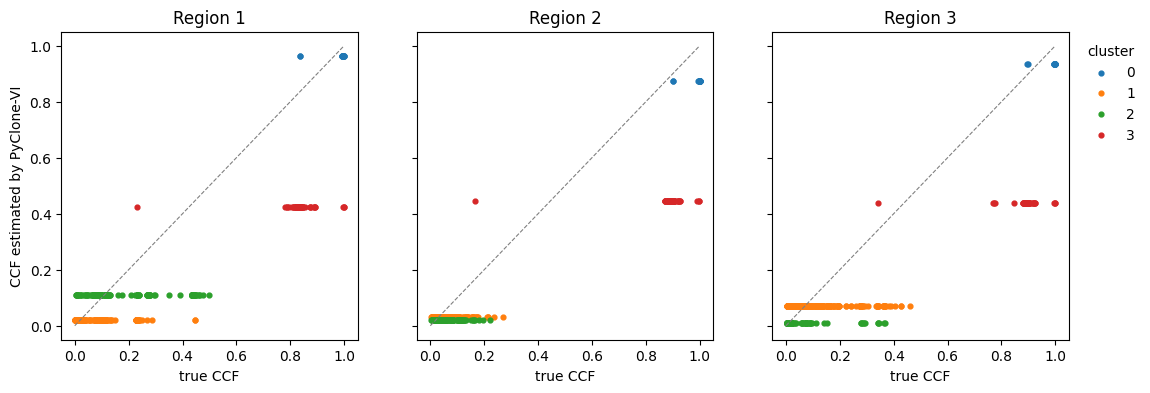

In [18]:
colors = dict(zip(sorted(result["cluster_id"].unique()), plt.get_cmap("tab10").colors))
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (r, part) in zip(axes, result.groupby("sample_id")):
    for c, points in part.groupby("cluster_id"):
        ax.scatter(points["true_ccf"], points["cellular_prevalence"], color=colors[c], s=12, label=c)
    ax.plot([0, 1], [0, 1], color="0.5", lw=0.8, ls="--")
    ax.set(title=r.replace("_", " ").capitalize(), xlabel="true CCF")
axes[0].set_ylabel("CCF estimated by PyClone-VI")
axes[-1].legend(title="cluster", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.show()

With the copy number and purity of ASCAT, PyClone-VI found 4 clusters for the 37 sets of clones, with a mean absolute error of 0.144 on the CCF and an adjusted Rand index of 0.27.
The clonal cluster 0 matches the mean true CCF of its 13 mutations within 0.11 in every region.
Cluster 3 holds 132 mutations that most cells of nearly every clone carry, at a true mean CCF of 0.83 to 0.89 in every region.
Its estimated CCF is 0.42 to 0.45, since the copy number at half of its true value halves the CCF that PyClone-VI derives from the allele fractions.
Cluster 2 holds 167 mutations, the most numerous of them those of clone 2, at a true mean CCF of 0.21 in region 1 and an estimated 0.11.
Cluster 1 contains most of the mutations at a low CCF, and many sets of clones contain only a few mutations, which lowers the adjusted Rand index.
The errors of the first tool of the chain therefore carry into the second, and scoring each step against the ground truth shows where they arise.

## Make the benchmark harder or easier

The settings of the tumor, the sampling and the assay change how hard this benchmark is, and [Shape the tumor](02_shape_the_tumor.ipynb) and [Shape the data](03_shape_the_data.ipynb) show their effects.
The settings of the tumor take effect when we grow a tumor from a configuration instead of loading a pregrown one.

- **Depth.** `mu_depth` sets the coverage, and at the 30x of standard WGS the logR and BAF are noisier and fewer subclonal mutations would reach three alternate reads.
- **Purity.** Regions with more stroma, or a whole-tissue dissociation, lower the purity, which makes the copy number harder to fit and lowers the allele fractions of every mutation.
- **Germline SNPs.** Fewer heterozygous germline sites (`het_frac` in `germline_params`) leave ASCAT fewer BAF values per arm.
- **Copy number.** A higher copy number rate (`cnv_prob` in `cell_params`), or genome doubling (`wgd_rate`), gives ASCAT more states to fit and puts more mutations on changed copy number.
- **Regions.** One region gives PyClone-VI one CCF per mutation, and more regions separate clusters that have the same CCF in one region.
- **Mutation burden.** The number of new point mutations per event (`n_snvs_per_allele` in `cell_params`) and the mutations of the founder cell (`founder_mutations`) set how many mutations there are to cluster.

The [`bulkDNA`](https://pedrofale.github.io/iscc/reference/bulkDNA/), [`Resection`](https://pedrofale.github.io/iscc/reference/Resection/) and [`GenotypeTumor`](https://pedrofale.github.io/iscc/reference/GenotypeTumor/) pages document every parameter.